In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Dataset load karein
df = pd.read_csv('diabetes_prediction_dataset.csv')
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [2]:
# SVM supervised algorithm hai, isliye 'diabetes' ko target (y) rakhenge
X = df.drop('diabetes', axis=1)
y = df['diabetes']

# Categorical columns ('gender', 'smoking_history') ko numeric mein badlein
X_encoded = pd.get_dummies(X, columns=['gender', 'smoking_history'], drop_first=True)
print("Encoded Features Shape:", X_encoded.shape)

Encoded Features Shape: (100000, 13)


In [3]:
# 80% Training aur 20% Testing data mein baantein
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Data ko scale karein (SVM ke liye scaling bahut zaroori hoti hai)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [4]:
svm_model = SVC(kernel='rbf', cache_size=1000, random_state=42)
svm_model.fit(X_train_scaled, y_train)

# Test data par prediction karein
y_pred = svm_model.predict(X_test_scaled)
print("Model Training Complete!")

Model Training Complete!


In [5]:
accuracy = accuracy_score(y_test, y_pred)
print(f"SVM Model Accuracy: {accuracy * 100:.2f}%\n")
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

SVM Model Accuracy: 96.36%

Classification Report:

              precision    recall  f1-score   support

           0       0.96      1.00      0.98     18300
           1       0.97      0.59      0.73      1700

    accuracy                           0.96     20000
   macro avg       0.96      0.80      0.86     20000
weighted avg       0.96      0.96      0.96     20000



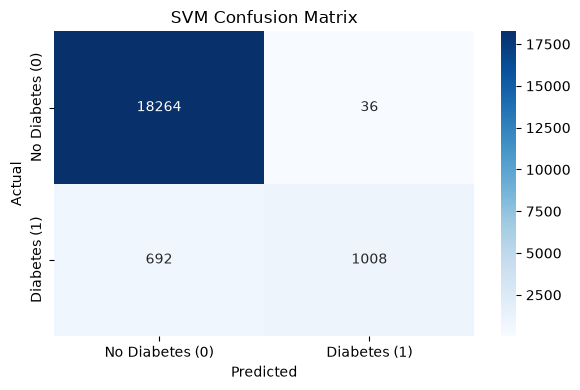

In [6]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['No Diabetes (0)', 'Diabetes (1)'],
    yticklabels=['No Diabetes (0)', 'Diabetes (1)']
)
plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()